Final Weights: [0.32022487 0.29293239]
Final Bias: 0.0
Epochs: 3


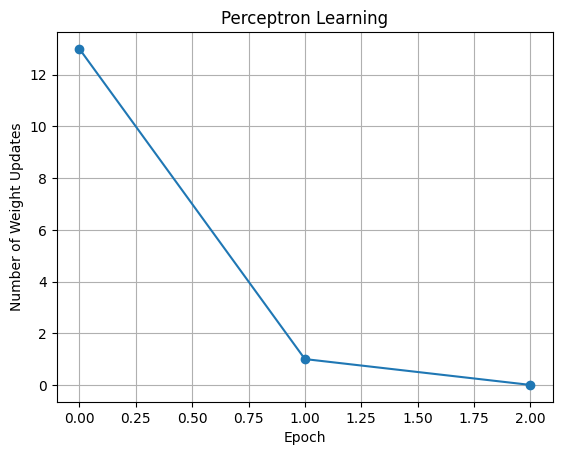

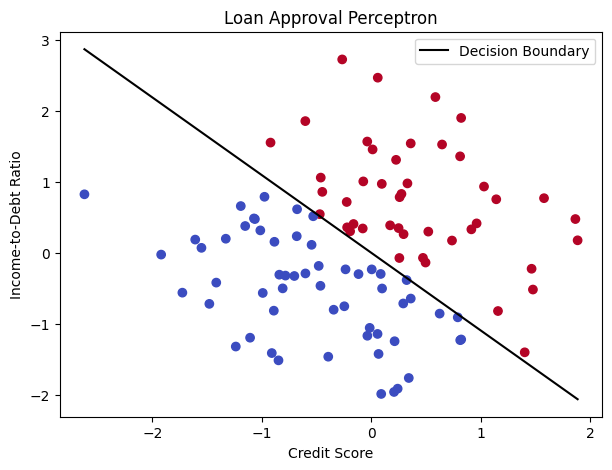


XOR Perceptron Errors: 4
XOR does not converge to zero error.


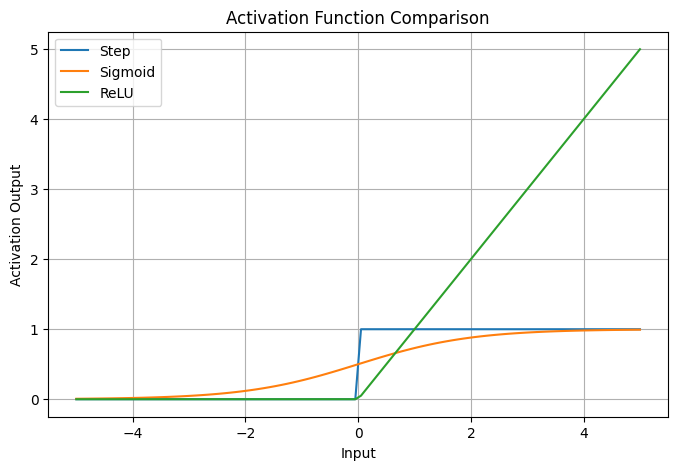

In [6]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# 1. Generate loan approval dataset
X = np.random.randn(100, 2)
y = (X[:, 0] + X[:, 1] > 0).astype(int)

# Step activation
def step(z):
    return (z >= 0).astype(int)

# 2. Train perceptron
weights = np.zeros(2)
bias = 0
lr = 0.1
updates = []

for epoch in range(50):
    count = 0

    for xi, target in zip(X, y):
        prediction = step(np.dot(xi, weights) + bias)
        error = target - prediction

        weights += lr * error * xi
        bias += lr * error
        count += abs(error)

    updates.append(count)

    if count == 0:
        break

print("Final Weights:", weights)
print("Final Bias:", bias)
print("Epochs:", len(updates))

# 3. Plot training updates
plt.plot(updates, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Number of Weight Updates")
plt.title("Perceptron Learning")
plt.grid()
plt.show()

# 4. Plot decision boundary
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm")

xx = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
yy = -(weights[0] * xx + bias) / weights[1]

plt.plot(xx, yy, color="black", label="Decision Boundary")
plt.xlabel("Credit Score")
plt.ylabel("Income-to-Debt Ratio")
plt.title("Loan Approval Perceptron")
plt.legend()
plt.show()

# 5. XOR dataset
X_xor = np.array([[0,0], [0,1], [1,0], [1,1]])
y_xor = np.array([0,1,1,0])

w = np.zeros(2)
b = 0

for epoch in range(20):
    errors = 0
    for xi, target in zip(X_xor, y_xor):
        pred = step(np.dot(xi, w) + b)
        error = target - pred
        w += 0.1 * error * xi
        b += 0.1 * error
        errors += abs(error)

print("\nXOR Perceptron Errors:", errors)
print("XOR does not converge to zero error.")

# 6. Compare activation functions
z = np.linspace(-5, 5, 100)

step_output = (z >= 0).astype(float)
sigmoid = 1 / (1 + np.exp(-z))
relu = np.maximum(0, z)

plt.figure(figsize=(8, 5))
plt.plot(z, step_output, label="Step")
plt.plot(z, sigmoid, label="Sigmoid")
plt.plot(z, relu, label="ReLU")
plt.xlabel("Input")
plt.ylabel("Activation Output")
plt.title("Activation Function Comparison")
plt.legend()
plt.grid()
plt.show()
